# 14. 사고다발지점 연관 도로 특성 분류 (링크 단위 재구성)

메인 속도 예측 파이프라인은 사고다발지역 여부(`accident_hotspot_count`)를 **입력 피처**로만 써왔다(기여도 +0.006~+0.010에 그침). 이 노트북은 라벨과 피처를 뒤집어, **사고다발지역 여부를 라벨**로 놓고 도로/지형/위상/시간/기상/속도/생활인구 피처가 이를 얼마나 설명하는지 본다.

## 이 버전에서 바뀐 것 (이전 시간 단위 버전 대비)

1. **시간 단위(15.1M행) → 링크 단위(63,548행) 집계**: 라벨이 링크당 고정값인데 같은 링크를 336번(시간대별) 복제해서 학습시키면 유효 표본이 뻥튀기된다. 대신 속도/강수/교통량을 링크별로 요약 통계(평균, 강수 시 하락폭, 첨두시 하락폭 등)로 압축해서 링크당 1행으로 만든다 — 강수 영향은 사라지는 게 아니라 `speed_rain_drop`(비 올 때 속도가 얼마나 떨어지는가) 같은 피처로 남는다.
2. **생활인구(격자/행정동) 피처 추가**: `사고다발지역` 지정 기준 자체가 보행량과 얽혀 있는데 기존 피처엔 보행량 프록시가 없었다. 250m 격자·행정동 생활인구를 링크별 평균/표준편차/최대값으로 요약해 추가한다.
3. **평가 방식을 200m 공간 블록으로 교체**: 링크 단위로 바꾸면 무작위 분할이 통하는 줄 알았는데, 실제로는 사고다발 링크의 91.8%가 다른 사고다발 링크로부터 50m 이내에 있다(같은 교차로가 여러 링크에 걸쳐 있어서). 무작위 분할·2km 블록 둘 다 시도해봤고, 무작위 분할은 위치를 암기해서 성능이 뻥튀기되고(PR-AUC 0.80) 2km는 너무 넓어 정당한 동네 단위 신호까지 날아간다(PR-AUC 0.09). 사고다발 zone 지름(~158m)에 맞춘 **200m 블록**이 같은 교차로 중복만 제거하고 동네 단위 신호(인구밀도 등)는 보존하는 절충점이다.
4. **하이퍼파라미터 튜닝**: `RandomizedSearchCV` + `GroupKFold(200m 블록)`로 정직한 기준에서 탐색한다(무작위 분할 기준으로 튜닝하면 의미 없는 파라미터가 나온다 — 실제로 그렇게 나온 파라미터를 200m 블록으로 재평가하면 성능이 반토막 났다).

## 라벨: 왜 보행자 단독인가

TAAS는 자전거/보행노인/보행어린이/스쿨존어린이 사고다발지역도 따로 공개하는데, 확인해보니 이 4종은 폴리곤 지름이 368~600m로 기존 보행자(158m)보다 2.3~3.8배 크다(스쿨존은 법정 반경 300m). 그대로 합치면 양성 링크가 3.8%→57.5%로 폭증해 "특정 위험지점"이라는 라벨의 의미가 사라진다. 버퍼 크기 정규화 없이 합치는 건 이번 범위에서 제외하고, **기존 보행자 라벨(158m, 2,438개 링크)을 그대로 쓴다.**

## 주의
- 양성비율 3.8%로 불균형 → PR-AUC/ROC-AUC를 accuracy 대신 사용
- `school_zone_count`/`speed_bump_count`는 사고 이후 안전대책으로 설치됐을 수 있어 역인과관계 가능 — 중요 피처로 나와도 "유발한다"가 아니라 "동행한다"로 해석
- `precip_mean`처럼 시간에 걸쳐 평균 낸 공간적으로 매끄러운 피처는 무작위 분할에서 사실상 "위치 좌표"처럼 작동해 성능을 부풀릴 수 있다(실측 확인됨) — 그래서 200m 블록 평가가 필수다
- 이번 노트북도 **학습/검증까지만** 다룬다(SHAP 등 심층 해석은 다음 단계)

In [1]:
import json
import platform
from pathlib import Path

import geopandas as gpd
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import randint, uniform
from shapely.geometry import shape
from sklearn.metrics import (
    PrecisionRecallDisplay,
    RocCurveDisplay,
    average_precision_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
)
from sklearn.model_selection import GroupKFold, RandomizedSearchCV

PROJECT_ROOT = Path.cwd().parent
RAW_DIR = PROJECT_ROOT / "data" / "raw"
INTERIM_DIR = PROJECT_ROOT / "data" / "interim"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIG_DIR = PROJECT_ROOT / "docs" / "figures" / "accident"
FIG_DIR.mkdir(parents=True, exist_ok=True)

DIMENSION_PATH = PROCESSED_DIR / "seoul_link_dimension.csv"   # pipeline/04 산출 (링크당 1행)
FACT_PATH = PROCESSED_DIR / "seoul_link_speed_fact.csv"       # pipeline/05 산출 (링크x날짜x시간)
LINK_SHP = INTERIM_DIR / "seoul_link.shp"

PEDESTRIAN_ACCIDENT_CSV = RAW_DIR / "traffic" / "pedestrian_accident_2019_2024.csv"

# 실험용(임시): 생활인구 — 아직 pipeline/04/05나 seoul_link_dimension.csv에는 안 붙임
GRID_MATCH_SHP = RAW_DIR / "traffic" / "match" / "match.shp"                 # 250M격자 CELL_ID -> geometry
GRID_POP_DIR = RAW_DIR / "traffic" / "250_LOCAL_RESD_202607"                 # 250m 격자 생활인구(일별)
DONG_POP_DIR = RAW_DIR / "traffic" / "250_LOCAL_RESD_ADMDONG_202607"         # 행정동 생활인구(일별)
POP_DATE_START, POP_DATE_END = "20260707", "20260720"                       # fact 기간과 동일(14일)

plt.rcParams["font.family"] = "AppleGothic" if platform.system() == "Darwin" else "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

RANDOM_STATE = 42
BLOCK_SIZE_M = 200      # 사고다발 zone 지름(~158m)과 양성 링크 군집 반경(91.8%가 50m 이내) 실측 기준
TEST_BLOCK_FRAC = 0.2
N_SEARCH_ITER = 40

COLOR_PR = "#2a78d6"
COLOR_ROC = "#eb6834"

## 1. 라벨: 보행자 사고다발지역 (링크 단위)

`pipeline/04_build_link_dimension.py`와 같은 방식(링크 geometry와 사고다발 폴리곤을 `sjoin(intersects)`)으로 직접 계산한다 — `seoul_link_dimension.csv`의 `accident_hotspot_count`와 동일한 값이어야 한다(검증용으로 함께 출력).

In [2]:
def parse_standard_json(s):
    return shape(json.loads(s))


ped = pd.read_csv(PEDESTRIAN_ACCIDENT_CSV, encoding="cp949")
ped = ped[ped["시도시군구명"].str.startswith("서울특별시")].copy()
ped_gdf = gpd.GeoDataFrame(
    {"사고건수": ped["사고건수"]},
    geometry=ped["다발지역폴리곤"].apply(parse_standard_json),
    crs="EPSG:4326",
).to_crs("EPSG:5179")
print(f"사고다발 zone 수: {len(ped_gdf)}")

link_full = gpd.read_file(LINK_SHP)[["LINK_ID", "geometry"]].to_crs("EPSG:5179")
link_full["LINK_ID"] = link_full["LINK_ID"].astype("int64")

joined = gpd.sjoin(link_full, ped_gdf, how="inner", predicate="intersects")
accident_count_by_link = joined.groupby("LINK_ID")["사고건수"].sum()

link_label = pd.DataFrame({"LINK_ID": link_full["LINK_ID"]})
link_label["accident_hotspot_count"] = link_label["LINK_ID"].map(accident_count_by_link).fillna(0)
link_label["accident_hotspot_binary"] = (link_label["accident_hotspot_count"] > 0).astype(int)

print(f"양성 링크: {link_label['accident_hotspot_binary'].sum():,} / {len(link_label):,} "
      f"({link_label['accident_hotspot_binary'].mean():.4f})")

# 검증: pipeline/04가 만든 dimension 테이블의 accident_hotspot_count와 일치해야 함
_dim_check = pd.read_csv(DIMENSION_PATH, usecols=["LINK_ID", "accident_hotspot_count"])
_match = (_dim_check.set_index("LINK_ID")["accident_hotspot_count"].fillna(0)
          == link_label.set_index("LINK_ID")["accident_hotspot_count"]).mean()
print(f"dimension 테이블과 일치율: {_match:.4f} (1.0이어야 정상)")

사고다발 zone 수: 191


양성 링크: 2,438 / 63,548 (0.0384)
dimension 테이블과 일치율: 1.0000 (1.0이어야 정상)


## 2. 속도·강수·교통량 링크 단위 집계

15.1M행(링크x날짜x시간)을 링크당 1행으로 압축한다. 단순 평균이 아니라 비/첨두시 조건부 평균으로 시간축의 정보를 남긴다 — `speed_rain_drop`(비 올 때 속도 하락폭), `speed_peak_drop`(첨두시 속도 하락폭)이 핵심이다.

In [3]:
fact = pd.read_csv(FACT_PATH)
fact["hour"] = fact["시간코드"].astype(int)
fact["is_rain"] = fact["precip_mm"] > 0
fact["is_peak"] = fact["hour"].isin([7, 8, 9, 18, 19, 20])
print(f"fact: {fact.shape}")

base_agg = fact.groupby("LINK_ID").agg(
    speed_mean=("평균속도", "mean"),
    speed_std=("평균속도", "std"),
    precip_mean=("precip_mm", "mean"),
    precip_max=("precip_mm", "max"),
    rain_hours_ratio=("is_rain", "mean"),
    traffic_mean=("traffic_volume_hourly", "mean"),
    traffic_std=("traffic_volume_hourly", "std"),
    traffic_max=("traffic_volume_hourly", "max"),
    sample_count_mean=("sample_count_5min", "mean"),
    obs_hours=("시간코드", "size"),
)

rain_speed = fact.pivot_table(index="LINK_ID", columns="is_rain", values="평균속도", aggfunc="mean")
rain_speed.columns = ["speed_dry_mean", "speed_rain_mean"]
rain_speed["speed_rain_drop"] = rain_speed["speed_dry_mean"] - rain_speed["speed_rain_mean"]

peak_speed = fact.pivot_table(index="LINK_ID", columns="is_peak", values="평균속도", aggfunc="mean")
peak_speed.columns = ["speed_offpeak_mean", "speed_peak_mean"]
peak_speed["speed_peak_drop"] = peak_speed["speed_offpeak_mean"] - peak_speed["speed_peak_mean"]

link_speed_agg = base_agg.join(rain_speed).join(peak_speed).reset_index()
print(f"link_speed_agg: {link_speed_agg.shape} ({link_speed_agg['LINK_ID'].nunique():,}개 링크)")
del fact

fact: (15094335, 11)


link_speed_agg: (44960, 17) (44,960개 링크)


## 3. 생활인구(격자/행정동) 링크 단위 집계

링크 중심점이 속하는 250m 격자(`CELL_ID`)를 찾고, 그 격자의 생활인구 시계열을 평균/표준편차/최대값으로 요약한다. 행정동은 격자 생활인구 파일 자체의 `행정동코드` 컬럼(인구 비중 최대인 행정동을 대표값으로)을 거쳐 구한다 — 경계 파일 없이도 가능하다.

In [4]:
link_pt = gpd.read_file(LINK_SHP)[["LINK_ID", "geometry"]]
link_pt["geometry"] = link_pt.geometry.centroid
link_pt = link_pt.to_crs("EPSG:5179")
link_pt["LINK_ID"] = link_pt["LINK_ID"].astype("int64")

grid_cells = gpd.read_file(GRID_MATCH_SHP)[["CELL_ID", "geometry"]]
link_cell = gpd.sjoin(link_pt, grid_cells, how="left", predicate="within")[["LINK_ID", "CELL_ID"]]
print(f"링크->격자 매칭: {link_cell['CELL_ID'].notna().sum():,} / {len(link_cell):,}")

pop_dates = [d.strftime("%Y%m%d") for d in pd.date_range(POP_DATE_START, POP_DATE_END)]

grid_parts = []
for d in pop_dates:
    f = GRID_POP_DIR / f"250_LOCAL_RESD_{d}.csv"
    part = pd.read_csv(f, encoding="cp949", usecols=["일자", "시간", "행정동코드", "250M격자", "생활인구합계"])
    part["생활인구합계"] = pd.to_numeric(part["생활인구합계"], errors="coerce").fillna(0)
    grid_parts.append(part)
grid_raw = pd.concat(grid_parts, ignore_index=True)
print(f"grid_raw: {grid_raw.shape}")

dong_parts = []
for d in pop_dates:
    f = DONG_POP_DIR / f"250_LOCAL_RESD_ADMDONG_{d}.csv"
    part = pd.read_csv(f, encoding="cp949", usecols=["일자", "시간", "행정동코드", "생활인구합계"])
    part["생활인구합계"] = pd.to_numeric(part["생활인구합계"], errors="coerce").fillna(0)
    dong_parts.append(part)
dong_raw = pd.concat(dong_parts, ignore_index=True)
print(f"dong_raw: {dong_raw.shape}")

링크->격자 매칭: 63,506 / 63,548


grid_raw: (3551636, 5)


dong_raw: (143472, 4)


In [5]:
# 셀 -> 대표 행정동(인구 비중 최대) — 경계에 걸친 셀은 여러 행정동에 인구가 나뉘어 기록됨
cell_dong_weight = grid_raw.groupby(["250M격자", "행정동코드"])["생활인구합계"].sum().reset_index()
cell_to_dong = cell_dong_weight.loc[cell_dong_weight.groupby("250M격자")["생활인구합계"].idxmax()].set_index("250M격자")["행정동코드"]
link_cell["행정동코드"] = link_cell["CELL_ID"].map(cell_to_dong)
print(f"링크->행정동(격자 경유) 매칭: {link_cell['행정동코드'].notna().sum():,} / {len(link_cell):,}")

# 셀 단위 (격자,일자,시간) 인구 — 경계 분할 행은 합산해서 셀 전체 인구로 복원한 뒤 시간축을 요약
grid_pop_hourly = grid_raw.groupby(["250M격자", "일자", "시간"])["생활인구합계"].sum().reset_index()
grid_pop_by_cell = grid_pop_hourly.groupby("250M격자")["생활인구합계"].agg(["mean", "std", "max"])
grid_pop_by_cell.columns = ["grid_pop_mean", "grid_pop_std", "grid_pop_max"]

dong_pop_by_dong = dong_raw.groupby("행정동코드")["생활인구합계"].agg(["mean", "std", "max"])
dong_pop_by_dong.columns = ["dong_pop_mean", "dong_pop_std", "dong_pop_max"]

link_grid_pop = link_cell[["LINK_ID", "CELL_ID"]].merge(
    grid_pop_by_cell, left_on="CELL_ID", right_index=True, how="left"
).drop(columns="CELL_ID")
link_dong_pop = link_cell[["LINK_ID", "행정동코드"]].merge(
    dong_pop_by_dong, left_on="행정동코드", right_index=True, how="left"
).drop(columns="행정동코드")

link_pop_agg = link_grid_pop.merge(link_dong_pop, on="LINK_ID", how="outer")
print(f"link_pop_agg: {link_pop_agg.shape}")
del grid_raw, dong_raw, grid_pop_hourly

링크->행정동(격자 경유) 매칭: 63,318 / 63,548


link_pop_agg: (63548, 7)


## 4. 최종 링크 단위 데이터셋 결합

`seoul_link_dimension.csv`(정적, 63,548행)에 속도 집계·생활인구 집계·라벨을 `LINK_ID`로 결합한다. 속도 집계가 없는 링크(5분 데이터 미관측, 29.25%)는 애초에 강수/첨두 반응성을 계산할 수 없으므로 `inner` join으로 제외한다 — 결과적으로 44,960개(A 계층) 링크만 남는다.

In [6]:
dimension = pd.read_csv(DIMENSION_PATH)
print(f"dimension: {dimension.shape}")

df = dimension.merge(link_speed_agg, on="LINK_ID", how="inner")
df = df.merge(link_pop_agg, on="LINK_ID", how="left")
df = df.merge(link_label[["LINK_ID", "accident_hotspot_binary"]], on="LINK_ID", how="left")

print(f"최종 링크 단위 데이터셋: {df.shape}")
print(f"양성 비율: {df['accident_hotspot_binary'].mean():.4f} ({df['accident_hotspot_binary'].sum():,} / {len(df):,})")
print(f"grid_pop 결측 없는 링크 비율: {df['grid_pop_mean'].notna().mean():.4f}")
print(f"dong_pop 결측 없는 링크 비율: {df['dong_pop_mean'].notna().mean():.4f}")

dimension: (63548, 59)
최종 링크 단위 데이터셋: (44960, 82)
양성 비율: 0.0450 (2,025 / 44,960)
grid_pop 결측 없는 링크 비율: 0.9958
dong_pop 결측 없는 링크 비율: 0.9958


## 5. 200m 공간 블록 배정

링크 중심점 좌표(EPSG:5179)를 200m 격자로 나눠 `block` 컬럼을 만든다. 이후 train/test 분리와 하이퍼파라미터 튜닝 모두 이 블록을 그룹으로 쓴다 — 같은 블록이 train/test에 걸치지 않게 한다.

In [7]:
link_xy = gpd.read_file(LINK_SHP)[["LINK_ID", "geometry"]]
link_xy["geometry"] = link_xy.geometry.centroid
link_xy = link_xy.to_crs("EPSG:5179")
link_xy["LINK_ID"] = link_xy["LINK_ID"].astype("int64")
link_xy["x"] = link_xy.geometry.x
link_xy["y"] = link_xy.geometry.y

df = df.merge(link_xy[["LINK_ID", "x", "y"]], on="LINK_ID", how="left")
df["block"] = (df["x"] // BLOCK_SIZE_M).astype(str) + "_" + (df["y"] // BLOCK_SIZE_M).astype(str)

print(f"블록 수: {df['block'].nunique():,}")
print(df.groupby("block")["accident_hotspot_binary"].mean().describe())

블록 수: 8,275
count    8275.000000
mean        0.033187
std         0.153697
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max         1.000000
Name: accident_hotspot_binary, dtype: float64


## 6. 피처/타깃 정리

`LINK_ID`/`F_NODE`/`T_NODE`/`ROAD_NAME`은 식별자라 제외. `accident_hotspot_count`(원본 사고건수)는 라벨의 원천이라 제외. `x`/`y`/`block`은 평가용 좌표라 피처에서 제외(모델이 좌표를 직접 외우는 것을 막기 위해).

In [8]:
ID_COLS = ["LINK_ID", "F_NODE", "T_NODE", "ROAD_NAME", "x", "y", "block"]
DROP_COLS = ["accident_hotspot_count"]
TARGET_COL = "accident_hotspot_binary"

CATEGORICAL_COLS = ["ROAD_RANK", "ROAD_TYPE", "ROAD_NO", "REST_VEH", "REST_W"]
for c in CATEGORICAL_COLS:
    df[c] = df[c].astype("category")

feature_cols = [c for c in df.columns if c not in ID_COLS + DROP_COLS + [TARGET_COL]]
X = df[feature_cols]
y = df[TARGET_COL]

print(f"피처 수: {len(feature_cols)}, 표본 수: {len(df):,}")
print(feature_cols)

피처 수: 76, 표본 수: 44,960
['LANES', 'ROAD_RANK', 'ROAD_TYPE', 'ROAD_NO', 'ROAD_USE', 'MULTI_LINK', 'CONNECT', 'MAX_SPD', 'REST_VEH', 'REST_W', 'REST_H', 'C-ITS', 'LENGTH', 'elev_start_m', 'elev_mid_m', 'elev_end_m', 'elev_mean_m', 'elev_min_m', 'elev_max_m', 'elev_delta_m', 'slope_pct', 'abs_slope_pct', 'f_node_node_in_degree', 'f_node_incoming_max_spd_mean', 'f_node_incoming_lanes_mean', 'f_node_node_out_degree', 'f_node_outgoing_max_spd_mean', 'f_node_outgoing_lanes_mean', 'f_node_node_total_degree', 't_node_node_in_degree', 't_node_incoming_max_spd_mean', 't_node_incoming_lanes_mean', 't_node_node_out_degree', 't_node_outgoing_max_spd_mean', 't_node_outgoing_lanes_mean', 't_node_node_total_degree', 'upstream_max_spd_mean', 'downstream_max_spd_mean', 'upstream_lanes_mean', 'downstream_lanes_mean', 'node_complexity', 'downstream_speed_delta', 'slope_pct_clipped', 'slope_outlier_flag', 'is_uphill', 'is_downhill', 'steep_uphill', 'slope_length_m', 'max_spd_x_lanes', 'length_x_node_complexi

## 7. Train/Test 블록 분리 + 하이퍼파라미터 튜닝

블록의 20%를 최종 held-out 테스트로 완전히 떼어놓고, 나머지 80%에서 `GroupKFold(5, groups=block)` + `RandomizedSearchCV`(40회, PR-AUC 기준)로 튜닝한다. 튜닝 자체도 200m 블록 기준으로 해야 뻥튀기된 파라미터를 고르지 않는다(무작위 분할로 튜닝했다가 200m 블록으로 재평가하니 성능이 반토막 났던 경험 참고).

In [9]:
rng = np.random.RandomState(RANDOM_STATE)
block_ids = df["block"].unique().to_numpy()  # ArrowStringArray는 in-place shuffle이 보장 안 돼 numpy로 변환
rng.shuffle(block_ids)
n_test_blocks = int(len(block_ids) * TEST_BLOCK_FRAC)
test_blocks = set(block_ids[:n_test_blocks])
is_test = df["block"].isin(test_blocks)

X_trainval, y_trainval, groups_trainval = X.loc[~is_test], y.loc[~is_test], df.loc[~is_test, "block"]
X_test, y_test = X.loc[is_test], y.loc[is_test]

print(f"trainval: {len(X_trainval):,}행 / {groups_trainval.nunique():,}개 블록 / 양성비율 {y_trainval.mean():.4f}")
print(f"test:     {len(X_test):,}행 / {is_test.sum():,}개 링크 / {len(test_blocks):,}개 블록 / 양성비율 {y_test.mean():.4f}")
assert not (set(groups_trainval) & test_blocks), "블록이 train/test에 겹칩니다"
print("train/test 블록 중복 없음 확인")

trainval: 35,936행 / 6,620개 블록 / 양성비율 0.0450
test:     9,024행 / 9,024개 링크 / 1,655개 블록 / 양성비율 0.0453
train/test 블록 중복 없음 확인


In [10]:
param_dist = {
    "num_leaves": randint(15, 127),
    "max_depth": randint(3, 12),
    "learning_rate": uniform(0.01, 0.14),
    "n_estimators": randint(100, 600),
    "min_child_samples": randint(5, 100),
    "reg_alpha": uniform(0, 2),
    "reg_lambda": uniform(0, 2),
    "colsample_bytree": uniform(0.5, 0.5),
    "subsample": uniform(0.5, 0.5),
}

scale_pos_weight = (y_trainval == 0).sum() / (y_trainval == 1).sum()
print(f"scale_pos_weight: {scale_pos_weight:.2f}")

base_model = lgb.LGBMClassifier(
    objective="binary",
    scale_pos_weight=scale_pos_weight,
    importance_type="gain",
    random_state=RANDOM_STATE,
    verbosity=-1,
    n_jobs=-1,
)
gkf = GroupKFold(n_splits=5)
search = RandomizedSearchCV(
    base_model,
    param_distributions=param_dist,
    n_iter=N_SEARCH_ITER,
    scoring="average_precision",
    cv=gkf,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1,
)
search.fit(X_trainval, y_trainval, groups=groups_trainval)

print(f"튜닝 CV(200m 블록) PR-AUC: {search.best_score_:.4f}")
print(f"최적 파라미터: {search.best_params_}")

scale_pos_weight: 21.24


Fitting 5 folds for each of 40 candidates, totalling 200 fits


튜닝 CV(200m 블록) PR-AUC: 0.3961
최적 파라미터: {'colsample_bytree': np.float64(0.8608647605824367), 'learning_rate': np.float64(0.04303788876485381), 'max_depth': 9, 'min_child_samples': 31, 'n_estimators': 492, 'num_leaves': 93, 'reg_alpha': np.float64(0.8550820367170993), 'reg_lambda': np.float64(0.05083825348819038), 'subsample': np.float64(0.5539457134966522)}


## 8. 최종 held-out 블록 평가

튜닝에 전혀 쓰이지 않은, 물리적으로 완전히 분리된 200m 블록에 대한 성능이다 — 이게 이 노트북에서 가장 신뢰할 수 있는 숫자다.

In [11]:
best_model = search.best_estimator_
y_proba = best_model.predict_proba(X_test)[:, 1]
y_pred = (y_proba >= 0.5).astype(int)

pr_auc = average_precision_score(y_test, y_proba)
roc_auc = roc_auc_score(y_test, y_proba)

print("=== 200m 블록 완전 분리 held-out 테스트 ===")
print(f"PR-AUC (Average Precision): {pr_auc:.4f}  (baseline={y_test.mean():.4f})")
print(f"ROC-AUC: {roc_auc:.4f}")
print()
print(classification_report(y_test, y_pred, target_names=["non-hotspot", "hotspot"]))

cm = confusion_matrix(y_test, y_pred)
print("Confusion matrix (rows=actual, cols=predicted@0.5):")
print(cm)

=== 200m 블록 완전 분리 held-out 테스트 ===


PR-AUC (Average Precision): 0.3375  (baseline=0.0453)
ROC-AUC: 0.8836

              precision    recall  f1-score   support

 non-hotspot       0.97      0.98      0.97      8615
     hotspot       0.45      0.28      0.34       409

    accuracy                           0.95      9024
   macro avg       0.71      0.63      0.66      9024
weighted avg       0.94      0.95      0.95      9024

Confusion matrix (rows=actual, cols=predicted@0.5):
[[8476  139]
 [ 296  113]]


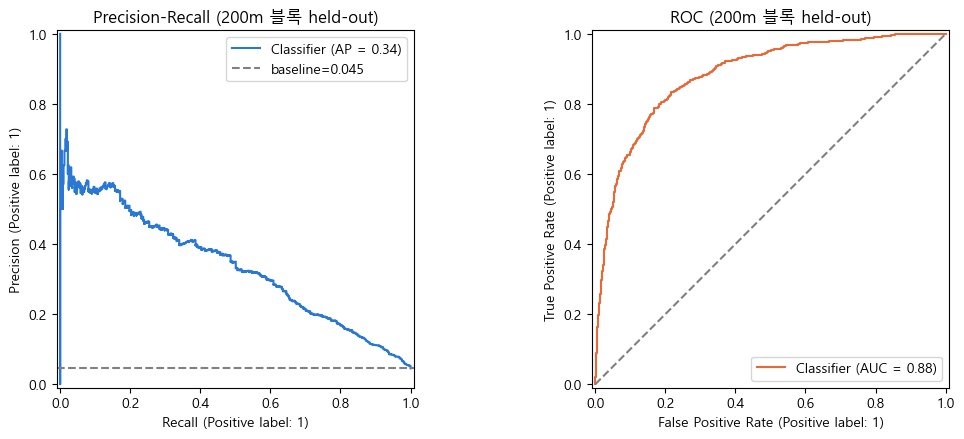

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

PrecisionRecallDisplay.from_predictions(y_test, y_proba, ax=axes[0], curve_kwargs={"color": COLOR_PR})
axes[0].axhline(y_test.mean(), color="gray", linestyle="--", label=f"baseline={y_test.mean():.3f}")
axes[0].set_title("Precision-Recall (200m 블록 held-out)")
axes[0].legend()

RocCurveDisplay.from_predictions(y_test, y_proba, ax=axes[1], curve_kwargs={"color": COLOR_ROC})
axes[1].plot([0, 1], [0, 1], color="gray", linestyle="--")
axes[1].set_title("ROC (200m 블록 held-out)")

fig.tight_layout()
fig.savefig(FIG_DIR / "01_pr_roc_curve.png", dpi=150)
plt.show()

## 9. 피처 중요도

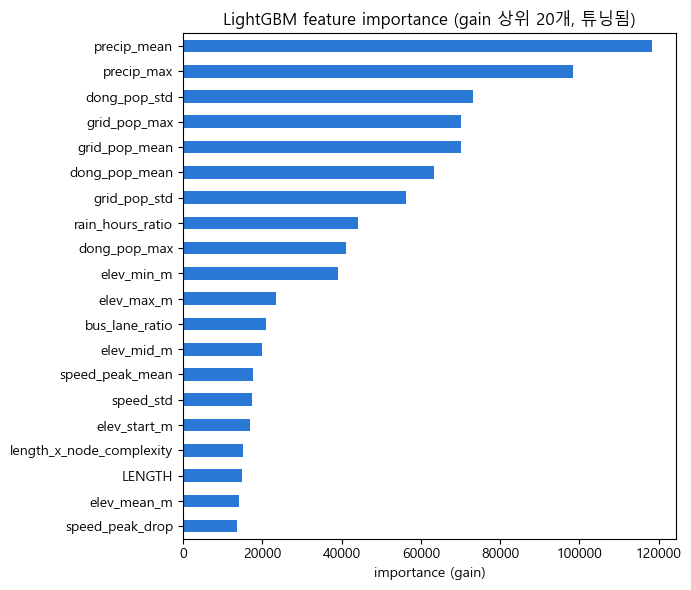

precip_mean                     118380.724967
precip_max                       98366.420067
dong_pop_std                     73069.583035
grid_pop_max                     70220.520608
grid_pop_mean                    70128.596366
dong_pop_mean                    63295.043339
grid_pop_std                     56287.434353
rain_hours_ratio                 44117.193310
dong_pop_max                     41017.839985
elev_min_m                       39024.610435
elev_max_m                       23482.555053
bus_lane_ratio                   20840.375749
elev_mid_m                       19869.440578
speed_peak_mean                  17596.303058
speed_std                        17310.958657
elev_start_m                     16994.948281
length_x_node_complexity         15145.438467
LENGTH                           14786.067494
elev_mean_m                      14076.935804
speed_peak_drop                  13689.226169
speed_rain_drop                  13586.774896
elev_end_m                       1

In [13]:
importance_all = (
    pd.Series(best_model.feature_importances_, index=feature_cols)
    .sort_values(ascending=False)
)
importance_all.name = "gain"

fig, ax = plt.subplots(figsize=(7, 6))
importance_all.head(20).iloc[::-1].plot.barh(ax=ax, color=COLOR_PR)
ax.set_title("LightGBM feature importance (gain 상위 20개, 튜닝됨)")
ax.set_xlabel("importance (gain)")
fig.tight_layout()
fig.savefig(FIG_DIR / "02_feature_importance.png", dpi=150)
plt.show()

pd.set_option("display.max_rows", None)
importance_all

## 10. 민감도 분석: 강수 절대수준 제거

`precip_mean`/`precip_max`(1·2위, 합쳐서 gain의 20.8%)는 2026년 7월 14일간 관측치인데, 라벨은 2019~2024년 5년간 누적 사고다. 시기가 겹치지 않아 "비가 사고를 유발한다"는 인과관계로 보기 어렵고, 레이더 강수가 공간적으로 매끄럽다는 점(예전에 x/y좌표와 상관 0.41~0.61 확인)까지 고려하면 200m 블록으로도 못 걸러낸 잔여 위치정보일 가능성이 있다.

재튜닝 없이(같은 블록 분할, 같은 하이퍼파라미터) `precip_mean`/`precip_max`/`rain_hours_ratio` 3개만 빼고 다시 학습해서, 순수하게 이 3개 피처의 한계기여도를 확인한다. `speed_rain_drop`(비 올 때 속도 하락폭)은 절대수준이 아니라 반응성이라 남겨둔다.

In [14]:
rain_absolute_cols = ["precip_mean", "precip_max", "rain_hours_ratio"]
feature_cols_no_rain = [c for c in feature_cols if c not in rain_absolute_cols]

model_no_rain = lgb.LGBMClassifier(
    objective="binary",
    scale_pos_weight=scale_pos_weight,
    importance_type="gain",
    random_state=RANDOM_STATE,
    verbosity=-1,
    n_jobs=-1,
    **search.best_params_,
)
model_no_rain.fit(X_trainval[feature_cols_no_rain], y_trainval)

y_proba_no_rain = model_no_rain.predict_proba(X_test[feature_cols_no_rain])[:, 1]
pr_auc_no_rain = average_precision_score(y_test, y_proba_no_rain)
roc_auc_no_rain = roc_auc_score(y_test, y_proba_no_rain)

print(f"제거 전({len(feature_cols)}개 피처): PR-AUC {pr_auc:.4f} / ROC-AUC {roc_auc:.4f}")
print(f"제거 후({len(feature_cols_no_rain)}개 피처): PR-AUC {pr_auc_no_rain:.4f} / ROC-AUC {roc_auc_no_rain:.4f}")
print(f"PR-AUC 변화: {pr_auc_no_rain - pr_auc:+.4f}  ({(pr_auc_no_rain / pr_auc - 1) * 100:+.1f}%)")

제거 전(76개 피처): PR-AUC 0.3375 / ROC-AUC 0.8836
제거 후(73개 피처): PR-AUC 0.3057 / ROC-AUC 0.8577
PR-AUC 변화: -0.0318  (-9.4%)


In [15]:
importance_no_rain = (
    pd.Series(model_no_rain.feature_importances_, index=feature_cols_no_rain)
    .sort_values(ascending=False)
)
importance_no_rain.name = "gain"
importance_no_rain.head(15)

dong_pop_mean               96156.218687
grid_pop_mean               94057.375644
dong_pop_std                91089.136260
grid_pop_max                86172.816620
grid_pop_std                75665.618989
dong_pop_max                64283.715632
elev_min_m                  40500.555660
elev_max_m                  34504.995604
elev_mid_m                  34007.402021
bus_lane_ratio              28139.258045
speed_peak_mean             24203.740841
speed_peak_drop             22195.311894
elev_end_m                  21805.852081
length_x_node_complexity    21493.188539
LENGTH                      19994.960528
Name: gain, dtype: float64

**해석**: 위 PR-AUC 변화폭이 이 노트북에서 가장 중요한 숫자 중 하나다 — 많이 떨어지면 `precip_mean`류가 실제로 신호를 나르고 있었다는 뜻(그래도 "비 때문"이라 단정하긴 이르고, 잔여 공간정보일 가능성은 여전히 남는다), 거의 안 떨어지면 애초에 노이즈에 가까웠다는 뜻이다.

**생활인구가 상위권을 휩쓰는 것에 대해**: 이건 이 라벨(사고다발지역) 자체의 근본적인 한계이지, 피처를 잘못 고른 게 아니다. TAAS의 "사고다발" 정의는 **사고 건수의 절대적 문턱값**(예: 7건 이상)이지, 유동인구로 나눈 **비율**이 아니다. 그러니 사람이 아예 안 다니는 골목은 아무리 위험한 도로 구조라도 사고가 7건까지 쌓일 기회 자체가 없어서 "사고다발"이 될 수 없고, 반대로 사람이 많으면 도로 구조가 평범해도 사고 기회가 많아 다발지역이 되기 쉽다. 즉 **지금 모델이 배우는 건 상당 부분 "이 라벨이 노출량(exposure)과 강하게 얽혀 있다"는 사실 자체**이지, "이 도로가 통행량 대비로도 위험하다"는 것과는 다르다. 후자를 보려면 사고건수를 유동인구로 나눈 "인구당 사고율" 같은 노출량 보정 라벨이 있어야 하는데, TAAS 원본 라벨엔 그런 정규화가 없다.

## 11. 민감도 분석: 생활인구 피처 축소

지금 생활인구 피처가 6개(`grid_pop_mean/std/max`, `dong_pop_mean/std/max`)라 너무 많다는 지적이 있어 상관관계를 먼저 확인했다: 격자 내부(mean-std-max)는 0.58~0.88, 행정동 내부는 0.78~0.96로 서로 중복이 심하지만, **격자와 행정동 사이는 상관관계가 낮다(0.07~0.45)** — 완전히 같은 정보는 아니라는 뜻이다. 그래서 각 그룹에서 서로 덜 겹치는 것만 남긴다: `grid_pop_mean`(격자 평균 수준), `grid_pop_std`(격자 내 시간대별 변동성, mean과 상관 0.58로 상대적으로 독립적), `dong_pop_mean`(행정동 평균 수준) 3개만 남기고 `grid_pop_max`/`dong_pop_std`/`dong_pop_max`는 뺀다. 강수와 마찬가지로 재튜닝 없이 같은 조건에서 비교한다.

In [16]:
pop_cols_to_drop = ["grid_pop_max", "dong_pop_std", "dong_pop_max"]
feature_cols_fewer_pop = [c for c in feature_cols if c not in pop_cols_to_drop]

model_fewer_pop = lgb.LGBMClassifier(
    objective="binary",
    scale_pos_weight=scale_pos_weight,
    importance_type="gain",
    random_state=RANDOM_STATE,
    verbosity=-1,
    n_jobs=-1,
    **search.best_params_,
)
model_fewer_pop.fit(X_trainval[feature_cols_fewer_pop], y_trainval)

y_proba_fewer_pop = model_fewer_pop.predict_proba(X_test[feature_cols_fewer_pop])[:, 1]
pr_auc_fewer_pop = average_precision_score(y_test, y_proba_fewer_pop)
roc_auc_fewer_pop = roc_auc_score(y_test, y_proba_fewer_pop)

print(f"원본({len(feature_cols)}개 피처): PR-AUC {pr_auc:.4f} / ROC-AUC {roc_auc:.4f}")
print(f"생활인구 축소({len(feature_cols_fewer_pop)}개 피처): PR-AUC {pr_auc_fewer_pop:.4f} / ROC-AUC {roc_auc_fewer_pop:.4f}")
print(f"PR-AUC 변화: {pr_auc_fewer_pop - pr_auc:+.4f}  ({(pr_auc_fewer_pop / pr_auc - 1) * 100:+.1f}%)")

원본(76개 피처): PR-AUC 0.3375 / ROC-AUC 0.8836
생활인구 축소(73개 피처): PR-AUC 0.3445 / ROC-AUC 0.8812
PR-AUC 변화: +0.0070  (+2.1%)


In [17]:
importance_fewer_pop = (
    pd.Series(model_fewer_pop.feature_importances_, index=feature_cols_fewer_pop)
    .sort_values(ascending=False)
)
importance_fewer_pop.name = "gain"
importance_fewer_pop.head(15)

grid_pop_mean                 116006.270017
precip_mean                   112626.806398
dong_pop_mean                 104116.923312
precip_max                     96714.306160
grid_pop_std                   94720.913825
rain_hours_ratio               52928.121901
elev_min_m                     40356.802434
elev_max_m                     33695.544203
bus_lane_ratio                 27944.555523
elev_mid_m                     25333.929594
elev_mean_m                    18742.265129
LENGTH                         18095.540939
length_x_node_complexity       18014.789827
speed_peak_drop                17156.401404
f_node_incoming_lanes_mean     16427.593314
Name: gain, dtype: float64

## 요약

| 평가 방식 | PR-AUC | ROC-AUC | 비고 |
|---|---|---|---|
| 시간 단위, LINK_ID GroupKFold | 0.39 | 0.85 | 이전 버전(참고용) |
| 링크 단위, 무작위 분할 | 0.80 | 0.98 | `precip_mean` 등이 위치 좌표처럼 작동해 뻥튀기됨 — 신뢰 불가 |
| 링크 단위, 2km 블록 | 0.09 | 0.67 | 정당한 동네 단위 신호까지 제거해 과도하게 보수적 |
| **링크 단위, 200m 블록(76개 피처)** | **0.34** | **0.88** | 사고다발 zone 실제 크기(~158m)에 맞춘 절충점 — 기준선 |
| 링크 단위, 200m 블록(강수 절대수준 3개 제거, 73개 피처) | 10절 참고 | 10절 참고 | 재튜닝 없이 동일 조건 비교 |
| 링크 단위, 200m 블록(생활인구 6→3개 축소, 73개 피처) | 11절 참고 | 11절 참고 | 재튜닝 없이 동일 조건 비교 |

모든 조건에서 베이스라인(양성비율 0.045) 대비 최소 수 배 이상의 신호는 유지된다 — 라벨이 노출량과 얽혀 있다는 한계는 있지만 "유의미한 결과가 없다"고 보기는 어렵다.

## 다음 단계 (범위 밖)
- SHAP summary/dependence plot으로 상위 피처의 방향성 확인, 특히 생활인구를 통제한 상태에서 도로 설계 피처가 추가로 설명하는 부분 확인
- 상관관계 높은 고도(7개)·노드위상(14개) 피처를 정리해 피처 수 축소(중복 제거)
- `school_zone_count`/`speed_bump_count`처럼 역인과관계 우려가 있는 피처를 제외한 모델과 비교
- 신규 4종(자전거/보행노인/보행어린이/스쿨존어린이) 사고다발지역을 버퍼 크기 정규화 후 결합해 라벨 확장
- 사고건수를 유동인구로 나눈 "노출량 보정" 라벨 버전과 비교(지금 라벨은 노출량과 강하게 얽혀 있음, 10절 참고)
- 사망자수/중상자수로 가중한 심각도 라벨 버전과 성능 비교
- held-out 블록 1개가 아니라 5-fold 전체 평균으로 안정성 확인